# 1. Introduction
- This notebook continues from 01-exploration.ipynb, using a different database (https://github.com/jfjelstul/worldcup - see details in README.md): 

## 2. Data Loading & Initial Exploration


### Import packages

In [194]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.colors as mcolors
import seaborn as sns
from seaborn import regplot
from datetime import datetime
import re
from pathlib import Path
import datetime 
from scipy import stats
from scipy.optimize import curve_fit
from scipy.stats import linregress
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
import statsmodels.api as sm

### Load Raw Data

In [195]:
# Contains squads data
fp9 = Path.cwd().parent/'data'/'squads.csv'
squads = pd.read_csv(fp9)

# Contains players data
fp10 = Path.cwd().parent/'data'/'players.csv'
players = pd.read_csv(fp10)

# Contains goals data
fp11 = Path.cwd().parent/'data'/'goals.csv'
goals = pd.read_csv(fp11)

# Contains data on the stages that teams got to
fp12 = Path.cwd().parent/'data'/'qualified_teams.csv'
quali_teams = pd.read_csv(fp12)

# Tournament stages for each team 
fp13 = Path.cwd().parent/'data'/'tournaments.csv'
tournaments = pd.read_csv(fp13)

# Data on team managers
fp14 = Path.cwd().parent/'data'/'manager_appointments.csv'
managers = pd.read_csv(fp14)

# Substitutions data
fp15 = Path.cwd().parent/'data'/'substitutions.csv'
subs = pd.read_csv(fp15)

# Data on who the host countries were each WC year
fp16 = Path.cwd().parent/'data'/'host_countries.csv'
hosts = pd.read_csv(fp16)

# Penalties and whether they were successful
fp17 = Path.cwd().parent/'data'/'penalty_kicks.csv'
penalties = pd.read_csv(fp17)

### Initial Exploration and Cleaning

In [196]:
''' Mask to exclude women's tournaments'''

mask = subs["tournament_name"].str.contains("Women")

In [197]:
subs = subs[~mask]
subs_by_year_by_team = subs.groupby(["tournament_id", "team_name"]).agg(subs_count = ("substitution_id", "count"))
subs_by_year_by_team.reset_index(inplace=True)

In [198]:
'''exclude women's tournaments'''

quali_teams = quali_teams[~quali_teams['tournament_name'].str.contains('Women', case=False)]

In [199]:
squads.head()

,key_id,tournament_id,tournament_name,team_id,team_name,team_code,player_id,family_name,given_name,shirt_number,position_name,position_code
0,1,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-69244,Bossio,Ángel,0,goal keeper,GK
1,2,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-23160,Botasso,Juan,0,goal keeper,GK
2,3,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-99230,Cherro,Roberto,0,forward,FW
3,4,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-41921,Chividini,Alberto,0,defender,DF
4,5,WC-1930,1930 FIFA Men's World Cup,T-03,Argentina,ARG,P-22739,Della Torre,José,0,defender,DF


In [200]:
players.head()

,key_id,player_id,family_name,given_name,birth_date,female,goal_keeper,defender,midfielder,forward,count_tournaments,list_tournaments,player_wikipedia_link
0,1,P-35894,A'Court,Alan,1934-09-30,0,0,0,0,1,1,1958,https://en.wikipedia.org/wiki/Alan_A%27Court
1,2,P-29915,Aarønes,Ann Kristin,1973-01-19,1,0,0,1,1,2,"1995, 1999",https://en.wikipedia.org/wiki/Ann_Kristin_Aar%...
2,3,P-03484,Aaronson,Brenden,2000-10-22,0,0,0,0,1,1,2022,https://en.wikipedia.org/wiki/Brenden_Aaronson
3,4,P-04189,Abadzhiev,Stefan,1934-07-03,0,0,0,0,1,1,1966,https://en.wikipedia.org/wiki/Stefan_Abadzhiev
4,5,P-03523,Abalo,Jean-Paul,1975-06-26,0,0,1,0,0,1,2006,https://en.wikipedia.org/wiki/Jean-Paul_Abalo


In [201]:
goals.head()

,key_id,goal_id,tournament_id,tournament_name,match_id,match_name,match_date,stage_name,group_name,team_id,...,shirt_number,player_team_id,player_team_name,player_team_code,minute_label,minute_regulation,minute_stoppage,match_period,own_goal,penalty
0,1,G-0001,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,0,T-30,France,FRA,19',19,0,first half,0,0
1,2,G-0002,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,0,T-30,France,FRA,40',40,0,first half,0,0
2,3,G-0003,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,0,T-30,France,FRA,43',43,0,first half,0,0
3,4,G-0004,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-46,...,0,T-46,Mexico,MEX,70',70,0,second half,0,0
4,5,G-0005,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,1930-07-13,group stage,Group 1,T-30,...,0,T-30,France,FRA,87',87,0,second half,0,0


In [202]:
tournaments.head()

,key_id,tournament_id,tournament_name,year,start_date,end_date,host_country,winner,host_won,count_teams,group_stage,second_group_stage,final_round,round_of_16,quarter_finals,semi_finals,third_place_match,final
0,1,WC-1930,1930 FIFA Men's World Cup,1930,1930-07-13,1930-07-30,Uruguay,Uruguay,1,13,1,0,0,0,0,1,0,1
1,2,WC-1934,1934 FIFA Men's World Cup,1934,1934-05-27,1934-06-10,Italy,Italy,1,16,0,0,0,1,1,1,1,1
2,3,WC-1938,1938 FIFA Men's World Cup,1938,1938-06-04,1938-06-19,France,Italy,0,15,0,0,0,1,1,1,1,1
3,4,WC-1950,1950 FIFA Men's World Cup,1950,1950-06-24,1950-07-16,Brazil,Uruguay,0,13,1,0,1,0,0,0,0,0
4,5,WC-1954,1954 FIFA Men's World Cup,1954,1954-06-16,1954-07-04,Switzerland,West Germany,0,16,1,0,0,0,1,1,1,1


In [203]:
tourn_winners_mens = tournaments[~tournaments['tournament_name'].str.contains('Women', case=False)]
tourn_winners_mens = tourn_winners_mens[['tournament_id', 'winner']]

In [204]:
''' get WC winners as list'''
winners_list = tourn_winners_mens['winner'].unique()
winners_list

<StringArray>
[     'Uruguay',        'Italy', 'West Germany',       'Brazil',
      'England',    'Argentina',       'France',        'Spain',
      'Germany']
Length: 9, dtype: str

In [205]:
'''exclude womens data'''
mens_squads = squads[~squads['tournament_name'].str.contains('Women', case=False)]

In [206]:
''' Merge useful data from the other datasets'''

mens_squads = pd.merge(mens_squads, players[['player_id', 'count_tournaments']], on='player_id', how='inner')
mens_squads = pd.merge(mens_squads, quali_teams[['team_id', 'tournament_id', 'performance', "count_matches"]], on=['team_id', 'tournament_id'], how='inner')
mens_squads = pd.merge(mens_squads, tournaments[['tournament_id', 'start_date']], on='tournament_id', how='inner')
mens_squads = pd.merge(mens_squads, subs_by_year_by_team, on=['tournament_id', 'team_name'], how='left')

In [207]:
performance_rank = {
    'group stage': 1,
    'round of 16': 2,
    'second group stage': 2,
    'quarter-finals': 3,
    'quarter-final': 3,
    'semi-finals': 4,
    'third-place match': 4,
    'final': 5
}
mens_squads['perform_rank'] = mens_squads['performance'].map(performance_rank)

In [208]:
''' Extract tournament year, merge and edit players birth dates to calculate age '''

mens_squads['tournament_year'] = mens_squads['tournament_id'].map(lambda x: x[-4:])
mens_squads = pd.merge(mens_squads, players[['player_id', 'birth_date']], on='player_id', how='inner')
mens_squads['birth_date_dt'] = pd.to_datetime(mens_squads['birth_date'], format='%Y-%m-%d', errors='coerce')
mens_squads['start_date_dt'] = pd.to_datetime(mens_squads['start_date'], format='%Y-%m-%d', errors='coerce')
mens_squads['age'] = (mens_squads['start_date_dt'] - mens_squads['birth_date_dt']).dt.days / 365.25

In [209]:
''' Rename a column for clarity'''

mens_squads.rename(columns={"count_matches": "team_total_matches"}, inplace=True)

In [210]:
'''furthest stage reached for each team grouped over all time'''

squad_performance_all_time = (mens_squads.groupby('team_name')['perform_rank']\
                    .agg(avg_performance_alltime='mean',median_performance_alltime='median',max_performance_alltime='max').reset_index())
squad_performance_all_time.sort_values("avg_performance_alltime", ascending=False).head(5)

,team_name,avg_performance_alltime,median_performance_alltime,max_performance_alltime
82,West Germany,4.300000,5.0,5.0
8,Brazil,3.425532,3.0,5.0
45,Netherlands,3.361446,3.0,5.0
28,Germany,3.174672,3.0,5.0
2,Argentina,3.082294,3.0,5.0


In [211]:
''' how many games did players play in each tournament (low avg = changing players a lot)'''

squad_experience = (mens_squads.groupby(['tournament_id', 'team_name', "team_total_matches"])\
                    .agg(avg_games_played=("count_tournaments", "mean"), median_games_played=("count_tournaments", "median")\
                         , max_games_played=("count_tournaments", "max"), round_reached= ("perform_rank", "max"), subs_count=("subs_count", "max")).reset_index())

In [212]:
''' Add subs per game column (divide by 2 as there are 2 rows per sub) '''

squad_experience["subs_per_game"] = (squad_experience["subs_count"] / squad_experience["team_total_matches"]) / 2

In [213]:
""" combines squad performance (all time average/max round reached) with squad experience (which is actually just the average games played per player for a given year of the WC)"""

squad_exp_perform = pd.merge(squad_experience, squad_performance_all_time, how='left', on='team_name')

In [214]:
''' add column 'ever_won_wc' to each row '''

squad_exp_perform['ever_won_wc'] = False
for idx, row in tourn_winners_mens.iterrows():
    filter = (squad_exp_perform['team_name'] == row['winner'])
    squad_exp_perform.loc[filter, 'ever_won_wc'] = True

In [215]:
''' Squad age vs success '''

age_v_perform = mens_squads.groupby(['tournament_id', 'team_name'])['age'].agg(avg_age='mean', median_age='median', max_age='max').reset_index()
age_v_perform.head()

,tournament_id,team_name,avg_age,median_age,max_age
0,WC-1930,Argentina,25.005165,24.748802,31.334702
1,WC-1930,Belgium,25.501369,24.049281,38.173854
2,WC-1930,Bolivia,25.167522,24.079398,32.301164
3,WC-1930,Brazil,24.857632,25.438741,30.253251
4,WC-1930,Chile,26.553694,26.685832,33.437372


In [216]:
''' Add the ages columns'''

squad_exp_perform = pd.merge(squad_exp_perform, age_v_perform, how='inner', on=['tournament_id', 'team_name'])      

## 3. Team Success

In [217]:
stage_order = ['Group Stage', 'Round of 16', 'Quarter Final', 'Semi Final', 'Final']

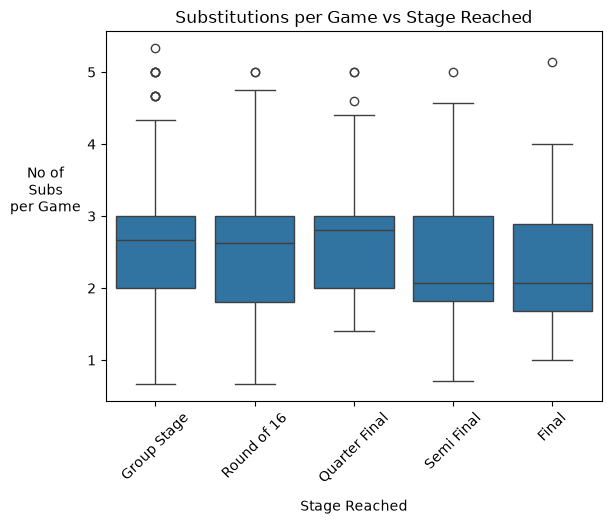

In [218]:
''' subs per game vs stage reached'''

sns.boxplot(data=squad_exp_perform, x='round_reached', y='subs_per_game')
plt.title('Substitutions per Game vs Stage Reached')
plt.ylabel('No of\nSubs\nper Game', rotation=0, labelpad=30)
plt.xlabel('Stage Reached', labelpad=10)
plt.xticks([0, 1, 2, 3, 4], labels=stage_order, rotation=45)
plt.show()

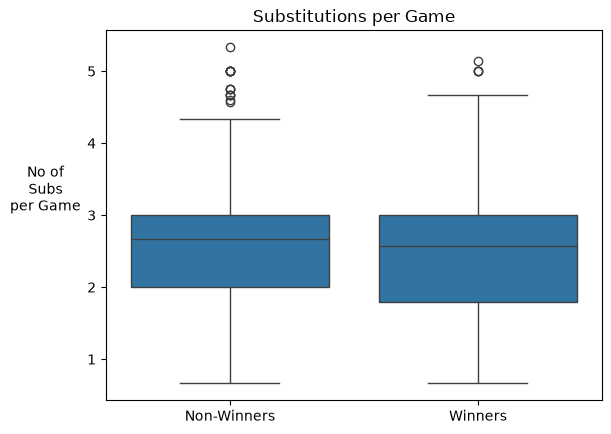

In [219]:
''' subs per game winner vs non-winner'''

sns.boxplot(data=squad_exp_perform, x='ever_won_wc', y='subs_per_game')
plt.title('Substitutions per Game')
plt.xticks([0, 1], ['Non-Winners', 'Winners'])
plt.xlabel(None)
plt.ylabel('No of\nSubs\nper Game', rotation=0, labelpad=30)
plt.show()

Text(0.5, 0, 'Stage Reached')

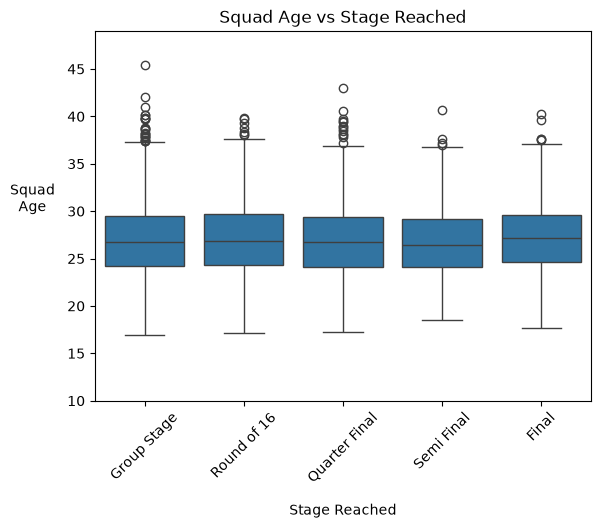

In [220]:
''' Squad age vs stage reached '''

sns.boxplot(data=mens_squads, x=mens_squads["perform_rank"], y=mens_squads["age"])
plt.ylim(bottom=10)
plt.ylabel('Squad\nAge', rotation=0, labelpad=25)
plt.title('Squad Age vs Stage Reached')
plt.xticks([0, 1, 2, 3, 4], labels=stage_order, rotation=45)
plt.xlabel('Stage Reached', labelpad=13)

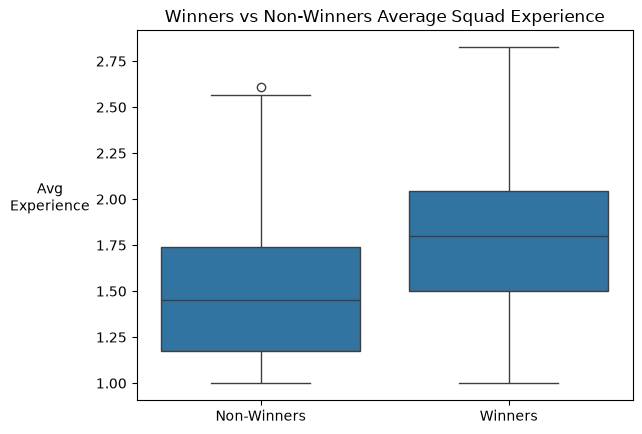

In [221]:
""" winners vs non winners in average games played """

winners_vs_exp = squad_exp_perform[['ever_won_wc', 'avg_games_played']]
sns.boxplot(data=winners_vs_exp, x='ever_won_wc', y='avg_games_played')
plt.xticks([0, 1], ['Non-Winners', 'Winners'])
plt.title('Winners vs Non-Winners Average Squad Experience')
plt.ylabel('Avg\nExperience', rotation=0, labelpad=33)
plt.xlabel(None)
plt.show()

Winning teams had more 'experience' as they simply played in more games. Therefore, this plot does not show meaningful insights.

### Squad positions composition

In [222]:
''' Assign new columns with the squad's position makeup'''

position_mix = (mens_squads.groupby(['team_name', 'tournament_id', 'position_name']).size().unstack(fill_value=0).reset_index())
position_mix.sample(5)

position_name,team_name,tournament_id,defender,forward,goal keeper,midfielder
88,Cameroon,WC-2010,8,5,3,7
181,Germany,WC-1938,5,9,3,5
418,Switzerland,WC-1934,5,10,3,5
271,Morocco,WC-2022,8,5,3,10
137,Dutch East Indies,WC-1938,4,8,2,5


In [223]:
'''Merge positions columns to dataframe'''

squad_exp_perform = pd.merge(squad_exp_perform , position_mix, on=['team_name', 'tournament_id'], how='inner')

In [224]:
''' Position proportions instead of counts - teams have diff squad sizes '''

position_cols = ['goal keeper', 'defender', 'midfielder', 'forward']

squad_exp_perform['squad_size'] = squad_exp_perform[position_cols].sum(axis=1)

for col in position_cols:
    squad_exp_perform[f'{col}_pct'] = (
        squad_exp_perform[col] / squad_exp_perform['squad_size']
    ) * 100

Text(0.5, 0, 'Stage Reached')

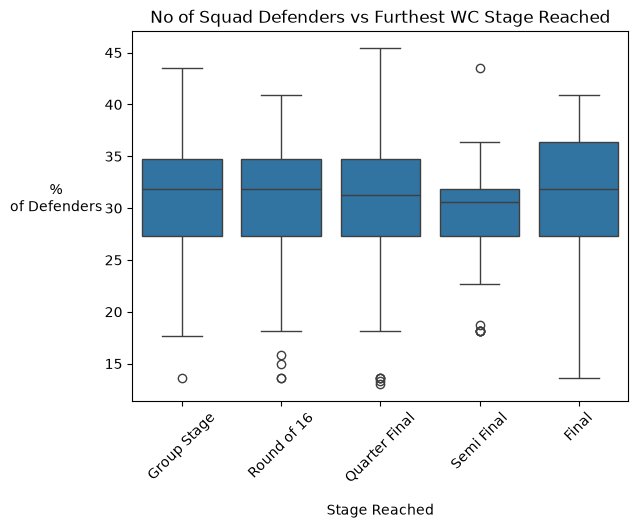

In [225]:
''' Position mix vs tournament progression '''

sns.boxplot(data=squad_exp_perform, x='round_reached', y='defender_pct')
plt.title('No of Squad Defenders vs Furthest WC Stage Reached')
plt.xticks([0, 1, 2, 3, 4], labels=stage_order, rotation=45)
plt.ylabel('%\nof Defenders', rotation=0, labelpad=35)
plt.xlabel('Stage Reached', labelpad=13)

No differences were observed for other position percentages. Defender % shown above as an example.

Text(0, 0.5, '%\nMidfielders')

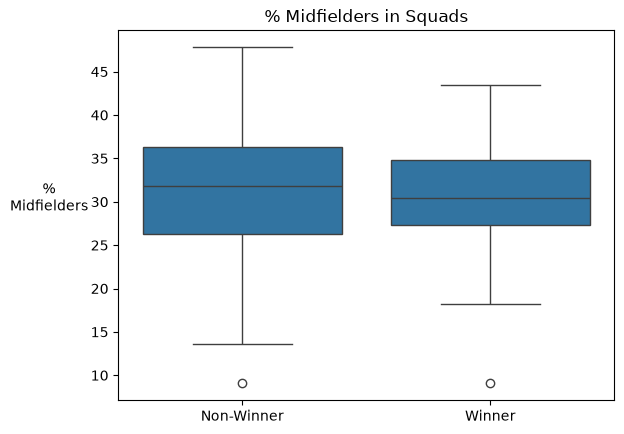

In [226]:
''' Position makeup of winners vs non-winners '''

sns.boxplot(data=squad_exp_perform, x='ever_won_wc', y='midfielder_pct')
plt.title('% Midfielders in Squads')
plt.xticks([0,1], ['Non-Winner', 'Winner'])
plt.xlabel(None)
plt.ylabel("%\nMidfielders", rotation=0, labelpad=30)

Text(0, 0.5, '%\nForwards')

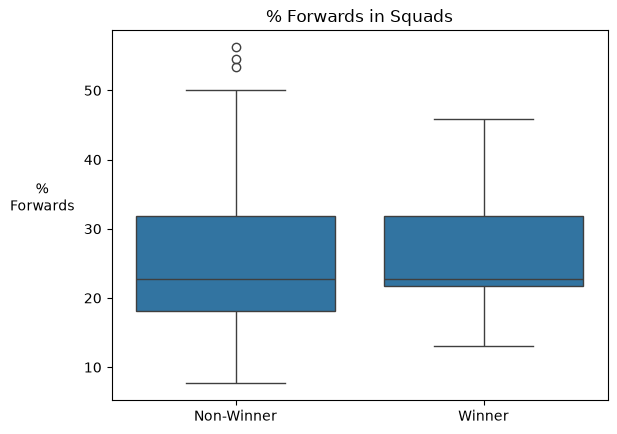

In [227]:
sns.boxplot(data=squad_exp_perform, x='ever_won_wc', y='forward_pct')
plt.title("% Forwards in Squads")
plt.xticks([0,1], ['Non-Winner', 'Winner'])
plt.xlabel(None)
plt.ylabel("%\nForwards", rotation=0, labelpad=30)

### Squad Positions Composition over Time for Top Winning Teams (Brazil, Italy, Argentina)

Text(0.5, 0, 'World Cup Year')

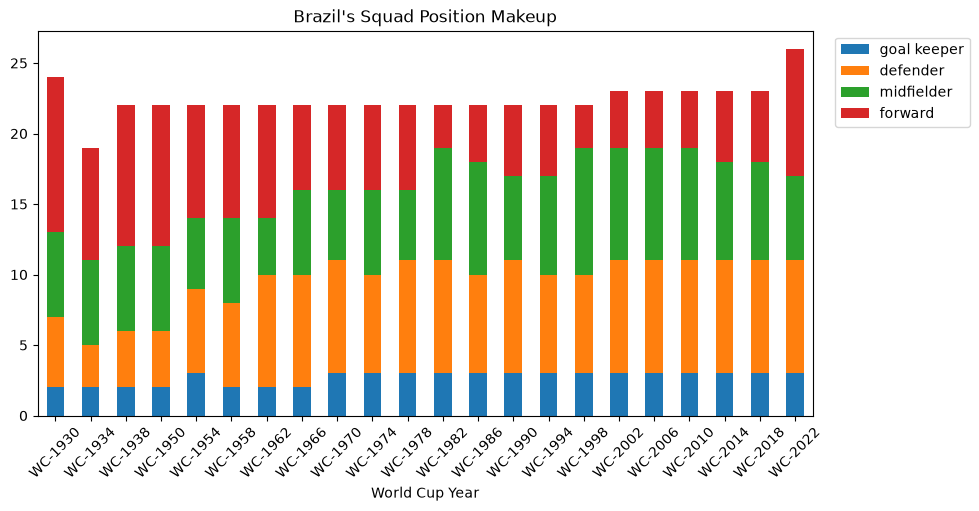

In [228]:
''' Brazil '''

brazil = squad_exp_perform[squad_exp_perform['team_name'] == 'Brazil']
brazil.set_index('tournament_id')[
    ['goal keeper', 'defender', 'midfielder', 'forward']
].plot(
    kind='bar',
    stacked=True,
    figsize=(10,5)
)
plt.title("Brazil's Squad Position Makeup")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xlabel("World Cup Year")

Text(0.5, 0, 'World Cup Year')

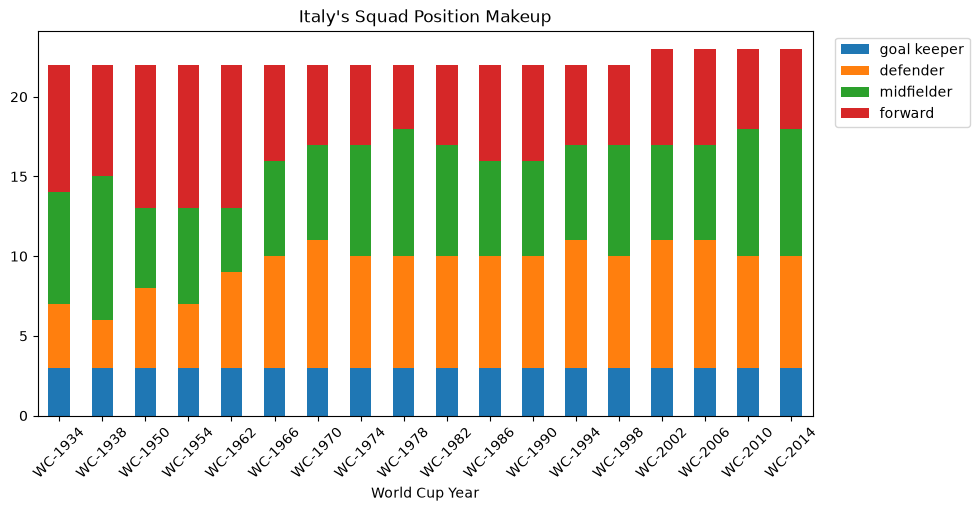

In [229]:
''' Italy '''
italy = squad_exp_perform[squad_exp_perform['team_name'] == 'Italy']
italy.set_index('tournament_id')[
    ['goal keeper', 'defender', 'midfielder', 'forward']
].plot(
    kind='bar',
    stacked=True,
    figsize=(10,5)
)
plt.title("Italy's Squad Position Makeup")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xlabel("World Cup Year")

Text(0.5, 0, 'World Cup Year')

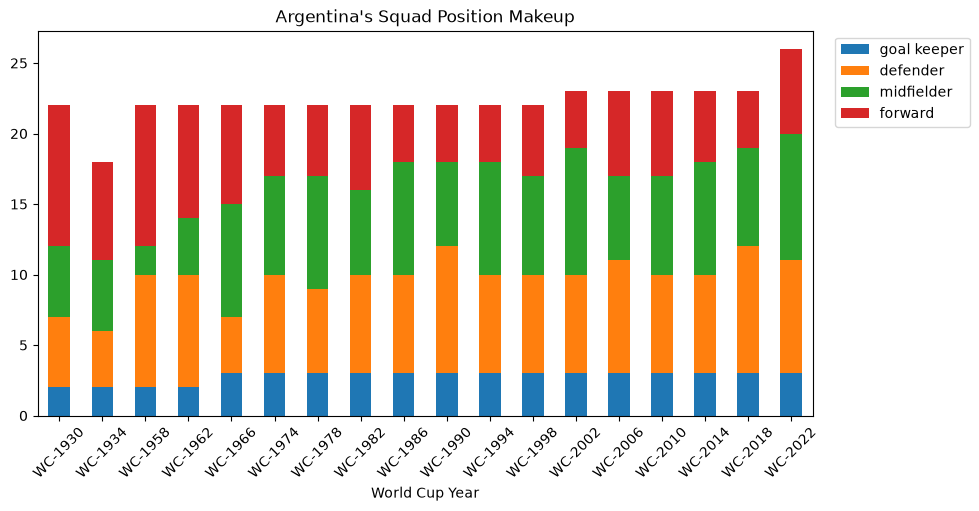

In [230]:
''' Argentina '''
argentina = squad_exp_perform[squad_exp_perform['team_name'] == 'Argentina']
argentina.set_index('tournament_id')[
    ['goal keeper', 'defender', 'midfielder', 'forward']
].plot(
    kind='bar',
    stacked=True,
    figsize=(10,5)
)
plt.title("Argentina's Squad Position Makeup")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xlabel("World Cup Year")

### Returning players between tournaments

In [231]:
''' Calculate returning players between tournaments'''

results = []

for team in mens_squads['team_name'].unique():
    team_df = mens_squads[mens_squads['team_name'] == team]
    tournaments = (team_df[['tournament_id', 'tournament_year']].drop_duplicates().sort_values('tournament_year'))
    tournament_list = tournaments['tournament_id'].tolist()
    for i in range(len(tournament_list) - 1):
        prev_tourn = tournament_list[i]
        next_tourn = tournament_list[i + 1]
        prev_squad = set(team_df.loc[team_df['tournament_id'] == prev_tourn,'player_id'])
        next_squad = set(team_df.loc[team_df['tournament_id'] == next_tourn,'player_id'])
        returning_players = len(prev_squad & next_squad)
        returning_pct = (returning_players / len(prev_squad)) * 100
        results.append({
            'team_name': team,
            'previous_tournament': prev_tourn,
            'next_tournament': next_tourn,
            'returning_players': returning_players,
            'previous_squad_size': len(prev_squad),
            'returning_players_pct': returning_pct
        })

stability_df = pd.DataFrame(results)

In [232]:
''' Merge columns from squad_exp_perfom dataframe'''

stability_df = stability_df.merge(squad_exp_perform[['team_name', 'tournament_id', 'round_reached', 'ever_won_wc']],
    left_on=['team_name', 'next_tournament'],
    right_on=['team_name', 'tournament_id'],
    how='left')

([<matplotlib.axis.XTick at 0x1b42da4bd40>,
 [Text(0, 0, 'Group Stage'),
  Text(1, 0, 'Round of 16'),
  Text(2, 0, 'Quarter Final'),
  Text(3, 0, 'Semi Final'),
  Text(4, 0, 'Final')])

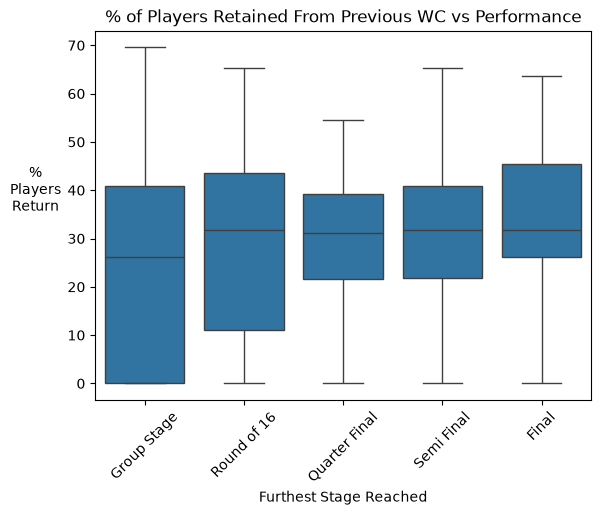

In [233]:
'''% of Players Retained From Previous WC vs Stage Reached'''

sns.boxplot(data=stability_df, x='round_reached', y='returning_players_pct',)
plt.title('% of Players Retained From Previous WC vs Performance')
plt.ylabel("%\nPlayers\nReturn", rotation=0, labelpad=23)
plt.xlabel("Furthest Stage Reached")
plt.xticks([0, 1, 2, 3, 4], labels=stage_order, rotation=45)

,returning_players,previous_squad_size,returning_players_pct,round_reached
count,404.000000,404.000000,404.000000,400.000000
mean,5.910891,22.173267,26.431708,2.167500
std,4.201734,1.037595,18.648510,1.318632
min,0.000000,15.000000,0.000000,1.000000
25%,2.000000,22.000000,8.695652,1.000000
50%,6.000000,22.000000,27.272727,2.000000
75%,9.000000,23.000000,40.909091,3.000000
max,16.000000,24.000000,69.565217,5.000000


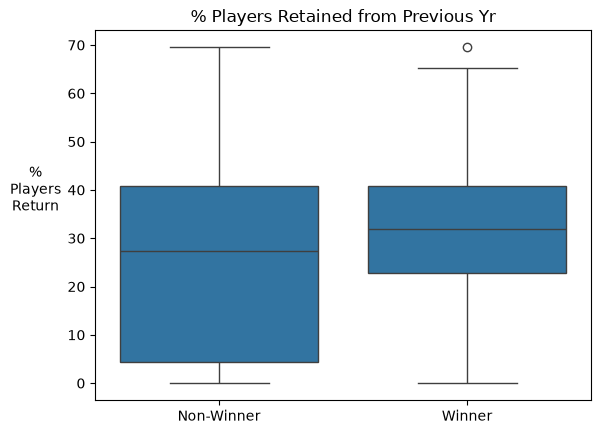

In [234]:
'''% Players Retained from Previous Yr (winners vs non-winners)'''

sns.boxplot(data=stability_df, x='ever_won_wc', y='returning_players_pct')
plt.title('% Players Retained from Previous Yr')
plt.ylabel("%\nPlayers\nReturn", rotation=0, labelpad=23)
plt.xticks([0,1], ['Non-Winner', 'Winner'])
plt.xlabel(None)

stability_df.describe()

Teams that eventually won the World Cup retained an average of X% of players from the previous tournament, compared with Y% for non-winners.

In [235]:
'''merge positions columsn to each goal'''

goals_with_pos = pd.merge(goals, mens_squads[['player_id', 'tournament_id', 'position_name']], on=['player_id', 'tournament_id'], how='left')

In [236]:
goals_by_position_pct = (goals_with_pos['position_name'].value_counts(normalize=True) * 100)
goals_by_position_pct

position_name
forward        64.264706
midfielder     25.588235
defender       10.036765
goal keeper     0.110294
Name: proportion, dtype: float64

In [237]:
team_goals_by_position = (goals_with_pos.groupby(['tournament_id', 'team_name', 'position_name']).size().unstack(fill_value=0).reset_index())

In [238]:
''' Merge ever_won_wc column '''

team_goals_by_position = team_goals_by_position.merge(
    squad_exp_perform[['tournament_id', 'team_name', 'ever_won_wc']],
    on=['tournament_id', 'team_name'],
    how='left'
)


In [239]:
team_goals_by_position_summary = team_goals_by_position.groupby('ever_won_wc')[['forward', 'midfielder', 'defender', 'goal keeper']].mean().reset_index()
team_goals_by_position_summary 

,ever_won_wc,forward,midfielder,defender,goal keeper
0,False,2.876133,1.268882,0.483384,0.006042
1,True,5.726619,1.985612,0.812950,0.007194


Text(0.5, 0, '')

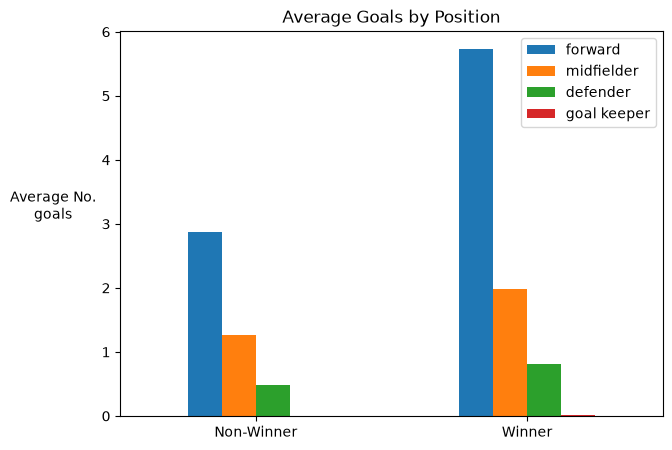

In [240]:
''' Average Goals by Position: Winners vs Non-Winners '''

team_goals_by_position_summary.plot(kind='bar',figsize=(7,5))
plt.ylabel('Average No.\ngoals', rotation=0, labelpad=35)
plt.title('Average Goals by Position')
plt.xticks(rotation=0)
plt.xticks([0,1], ['Non-Winner', 'Winner'])
plt.xlabel(None)

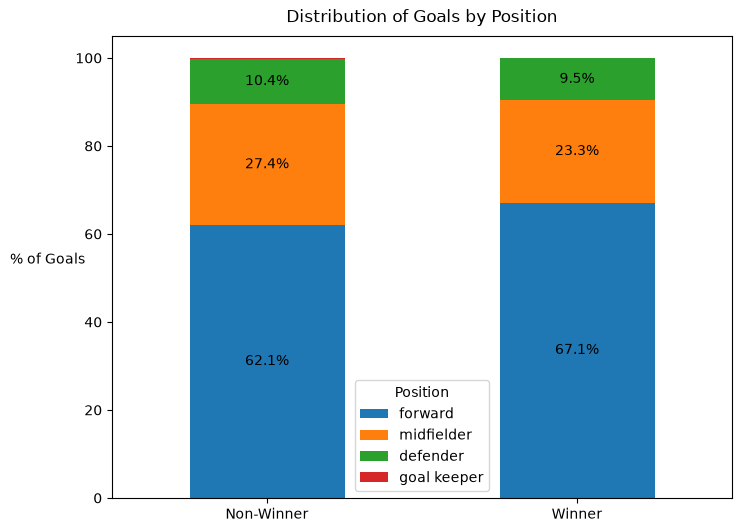

In [241]:
''' Get percentage of goals scored by each position rather than raw count'''

pct_df = team_goals_by_position_summary.set_index("ever_won_wc")
pct_df = pct_df.div(pct_df.sum(axis=1), axis=0) * 100

ax = pct_df.plot(kind='bar', stacked=True,figsize=(8, 6))

for container in ax.containers:
    labels = [f'{v:.1f}%' if v > 5 else '' for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center',fmt='%.1f%%')

plt.ylabel('% of Goals', rotation=0, labelpad=20)
plt.xlabel('Winner')
plt.title('Distribution of Goals by Position', pad=10)
plt.xticks([0,1], ['Non-Winner', 'Winner'], rotation=0)
plt.xlabel(None)
handles, labels = ax.get_legend_handles_labels()
plt.legend(title='Position')
plt.show()

Winning teams get slightly more goals from forwards.

## 4. Team Playing Style

In [242]:
''' Goal contribution diversity '''

unique_scorers = goals.groupby(['team_name', 'tournament_id']).agg(no_goals=('goal_id', 'count'), scoring_players=('player_id', list))
unique_scorers['unique_scoring_players'] = unique_scorers['scoring_players'].map(lambda x: list(set(x)))
unique_scorers['no_unique_scorers'] = unique_scorers['unique_scoring_players'].apply(len)
unique_scorers_summary = unique_scorers.drop(['scoring_players', 'unique_scoring_players'], axis=1).reset_index()
squad_exp_perform = pd.merge(squad_exp_perform, unique_scorers_summary, on=['tournament_id', 'team_name'], how='left')
squad_exp_perform['no_uniq_scorer_per_goal'] = squad_exp_perform['no_goals'] / squad_exp_perform['no_unique_scorers']

Text(0, 0.5, 'No.\nUnique\nScorers\nper Goal')

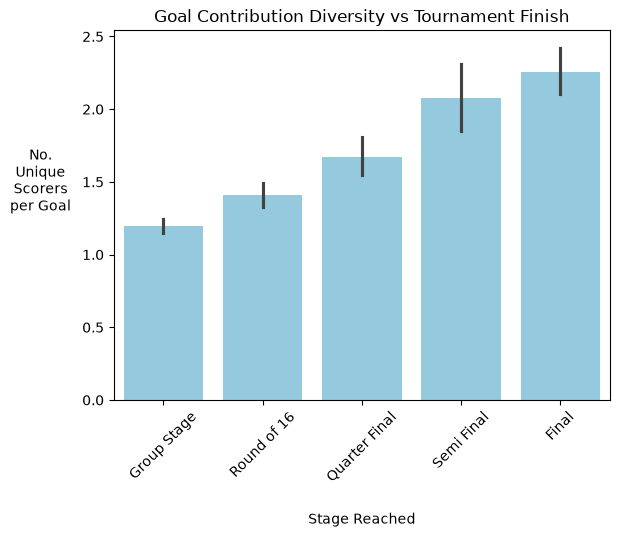

In [243]:
''' Goal Contribution Diversity vs Tournament Finish '''

sns.barplot(data=squad_exp_perform, x='round_reached', y='no_uniq_scorer_per_goal', color='skyblue')
plt.xticks([float(n) for n in range(5)], stage_order, rotation=45)
plt.title('Goal Contribution Diversity vs Tournament Finish')
plt.xlabel('Stage Reached', labelpad=20)
plt.ylabel('No.\nUnique\nScorers\nper Goal', rotation=0, labelpad=30)

In [244]:
''' Add column wc_winner to goals'''

goals['wc_winner'] = goals['team_name'].isin(tourn_winners_mens["winner"])
goals['goal_minute'] = goals['minute_regulation'] + goals['minute_stoppage'].fillna(0)

In [245]:
def make_bins(bins:list) -> list:
    '''Creates 5-min-interval bins to place goal minute into'''
    labels = []
    for n, idx in enumerate(bins):
        if n == 0:
            continue
        labels.append(f"{bins[n-1]}-{idx}")
    return labels

intervals = list(range(0,120,5))
goals['minute_bin'] = pd.cut(goals['goal_minute'],
    bins=intervals,
    labels=make_bins(intervals),
    include_lowest=True
)

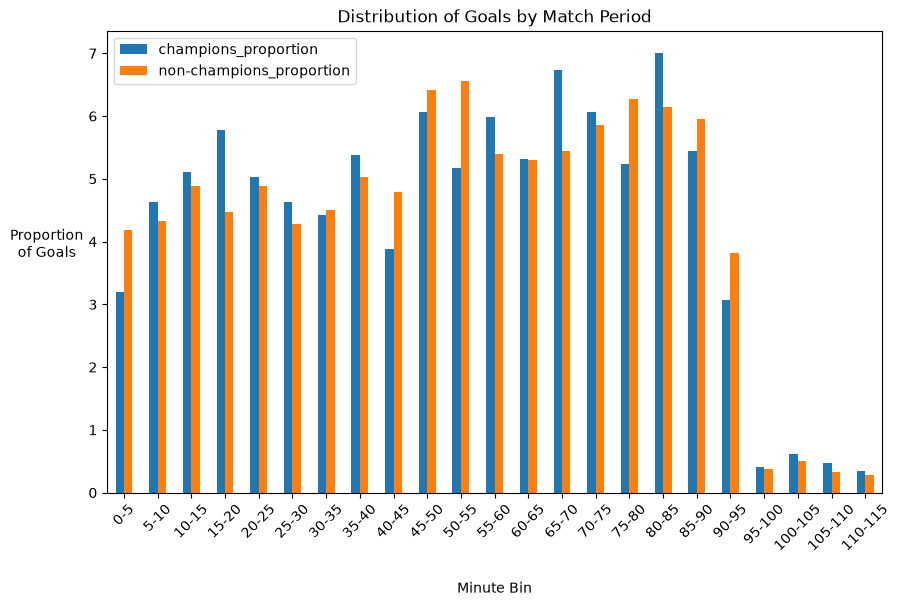

In [246]:
'''Distribution of Goals by Match Period'''

champion_goals = goals[goals['wc_winner']]
# Champions
champ_dist = (
    champion_goals['minute_bin']
    .value_counts(normalize=True)
    .sort_index().reset_index().rename(columns={'proportion': 'champions_proportion'}))
# Non-Champions
nonchamp_dist = (
    goals[~goals['wc_winner']]
    ['minute_bin']
    .value_counts(normalize=True)
    .sort_index().reset_index().rename(columns={'proportion': 'non-champions_proportion'}))


concat_dist = pd.merge(champ_dist, nonchamp_dist, on='minute_bin', how='inner')
concat_dist[["non-champions_proportion", "champions_proportion"]] = concat_dist[["non-champions_proportion", "champions_proportion"]] * 100

concat_dist.set_index('minute_bin').plot(
    kind='bar',
    figsize=(10, 6)
)
plt.title('Distribution of Goals by Match Period')
plt.xlabel('Minute Bin', labelpad=20)
plt.ylabel('Proportion\nof Goals', rotation=0, labelpad=30)
plt.xticks(rotation=45)
plt.show()

### Managers analysis

In [247]:
'''Add column to see if manager is from the country they are managing'''

managers['mger_from_team_country'] = managers.apply(lambda row: True if row['team_name'] == row['country_name'] else False, axis=1)

In [248]:
''' percent/number of teams where manager is from teams country '''

manager_from_team_country = managers.groupby('team_name').agg(from_team_country_sum=('mger_from_team_country', 'sum'), total=('mger_from_team_country', 'size')).reset_index()
manager_from_team_country['pct_from_team_country'] = round((manager_from_team_country['from_team_country_sum'] / manager_from_team_country['total']) * 100)
manager_from_team_country['wc_winner'] = manager_from_team_country.apply(lambda row: True if row['team_name'] in (tourn_winners_mens['winner'].to_list()) else False, axis=1)
manager_from_team_country.head()

,team_name,from_team_country_sum,total,pct_from_team_country,wc_winner
0,Algeria,4,5,80.0,False
1,Angola,1,1,100.0,False
2,Argentina,21,22,95.0,True
3,Australia,6,13,46.0,False
4,Austria,8,8,100.0,False


C:\Users\bevamin\AppData\Local\Temp\ipykernel_34436\3051312348.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


Text(0.5, 1.0, "% of managers from team's country")

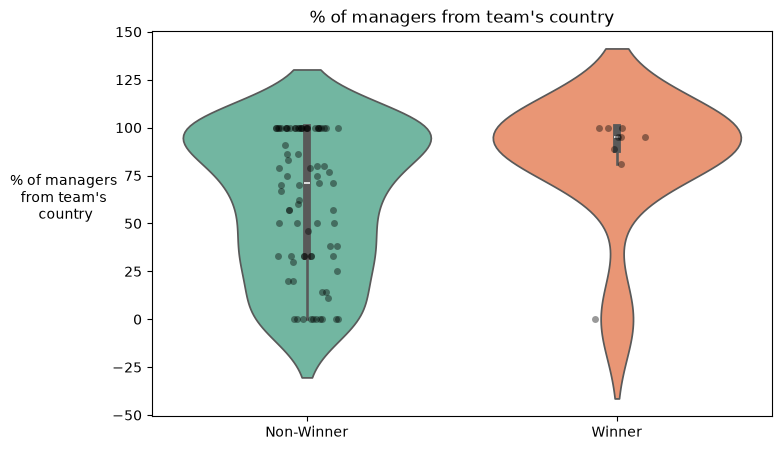

In [249]:
''' % managers from teams country vs success'''

plt.figure(figsize=(8,5))

sns.violinplot(
    data=manager_from_team_country,
    x='wc_winner',
    y='pct_from_team_country',
    inner='box', palette='Set2'
)

sns.stripplot(
    data=manager_from_team_country,
    x='wc_winner',
    y='pct_from_team_country',
    color='black',
    alpha=0.4
)

plt.ylabel("% of managers\nfrom team's\n country", rotation=0, labelpad=35)
plt.xticks([0,1], ['Non-Winner', 'Winner'], rotation=0)
plt.xlabel(None)
plt.title("% of managers from team's country")


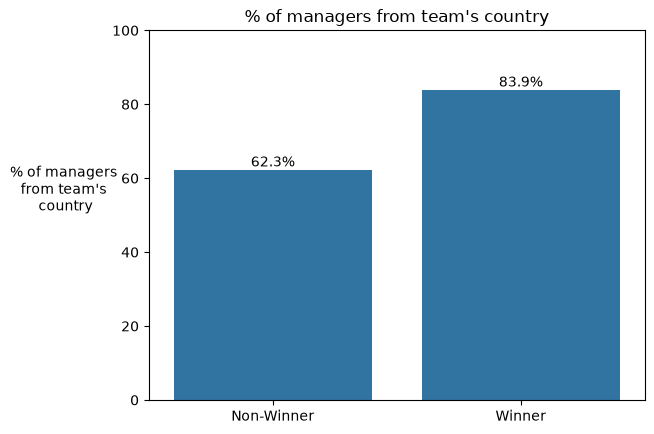

In [250]:
''' Similar to plot above but has percentages, no spread'''

winner_summary = (
    manager_from_team_country
    .groupby('wc_winner')['pct_from_team_country']
    .mean()
    .reset_index()
)

ax = sns.barplot(
    data=winner_summary,
    x='wc_winner',
    y='pct_from_team_country'
)
plt.title("% of managers from team's country")
plt.ylabel("% of managers\nfrom team's\n country", rotation=0, labelpad=35)
plt.xticks([0,1], ['Non-Winner', 'Winner'], rotation=0)
plt.xlabel(None)
plt.ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%')

Winning nations had managers from their own country in 83.9% of tournaments, compared with 62.3% for non-winning nations.

### Host countries analysis

In [251]:
''' host countries '''

hosts['performance'].unique()

<StringArray>
[         'champions',      'quater-finals',         'runners-up',
      'quarter-final',        'third place', 'second group stage',
     'quarter-finals',        'round of 16',       'fourth place',
        'group stage']
Length: 10, dtype: str

In [252]:
'''Data cleaning - typos in dataset, remove women's tournaments'''

hosts.loc[(hosts['performance'] == 'quarter-final') | (hosts['performance'] == 'quater-finals'), 'performance'] = 'quarter-finals'
mens_hosts = hosts[~hosts['tournament_name'].str.contains('Women')]

In [253]:
''' stages mapping'''

stages = {'group stage': 1, 'second group stage': 2, 'round of 16' : 2, \
           'quarter-finals': 3, 'fourth place': 4, 'third place': 4, 'runners-up': 5, 'champions': 5}
stages_order = stages.keys()
stages_order

stage_names = ["group stage", "round of 16", "quarter finals", "semi finals", "finals"]

In [254]:
mens_hosts['perform_map'] = mens_hosts['performance'].map(stages)
mens_hosts.head()

,key_id,tournament_id,tournament_name,team_id,team_name,team_code,performance,perform_map
0,1,WC-1930,1930 FIFA Men's World Cup,T-84,Uruguay,URY,champions,5
1,2,WC-1934,1934 FIFA Men's World Cup,T-41,Italy,ITA,champions,5
2,3,WC-1938,1938 FIFA Men's World Cup,T-30,France,FRA,quarter-finals,3
3,4,WC-1950,1950 FIFA Men's World Cup,T-09,Brazil,BRA,runners-up,5
4,5,WC-1954,1954 FIFA Men's World Cup,T-75,Switzerland,CHE,quarter-finals,3


In [255]:
mens_hosts_agg = mens_hosts.groupby('perform_map')['perform_map'].count().reset_index(name='count')
mens_hosts_agg["stage"] = stage_names

In [256]:
sum_of_finishes_hosts = mens_hosts_agg["count"].sum()
mens_hosts_agg["proportion"] = (mens_hosts_agg["count"] / sum_of_finishes_hosts)*100
mens_hosts_agg.head()

,perform_map,count,stage,proportion
0,1,2,group stage,8.695652
1,2,3,round of 16,13.043478
2,3,5,quarter finals,21.739130
3,4,5,semi finals,21.739130
4,5,8,finals,34.782609


In [257]:
mens_hosts_agg.sort_values(by='perform_map', ascending=False)

,perform_map,count,stage,proportion
4,5,8,finals,34.782609
3,4,5,semi finals,21.739130
2,3,5,quarter finals,21.739130
1,2,3,round of 16,13.043478
0,1,2,group stage,8.695652


In [258]:
squad_exp_perform = pd.merge(squad_exp_perform, mens_hosts.rename(columns={'team_name': 'host_name'}), on='tournament_id', how='left')

In [259]:
squad_exp_perform.drop('performance', axis=1, inplace=True)

In [260]:
''' Dataframe for rows where team was not the host '''

squad_exp_perform_nonhosts = squad_exp_perform[squad_exp_perform['host_name']!= squad_exp_perform['team_name']]
squad_exp_perform_nonhosts = squad_exp_perform_nonhosts.groupby('round_reached')["round_reached"].count().reset_index(name="count")

In [261]:
'''Non-hosts proportions across stages '''

squad_exp_perform_nonhosts["stage"] = stage_names
sum_of_finishes = squad_exp_perform_nonhosts["count"].sum()
squad_exp_perform_nonhosts["proportion"] = (squad_exp_perform_nonhosts["count"] / sum_of_finishes) * 100
squad_exp_perform_nonhosts.head()

,round_reached,count,stage,proportion
0,1.0,236,group stage,47.676768
1,2.0,116,round of 16,23.434343
2,3.0,67,quarter finals,13.535354
3,4.0,39,semi finals,7.878788
4,5.0,37,finals,7.474747


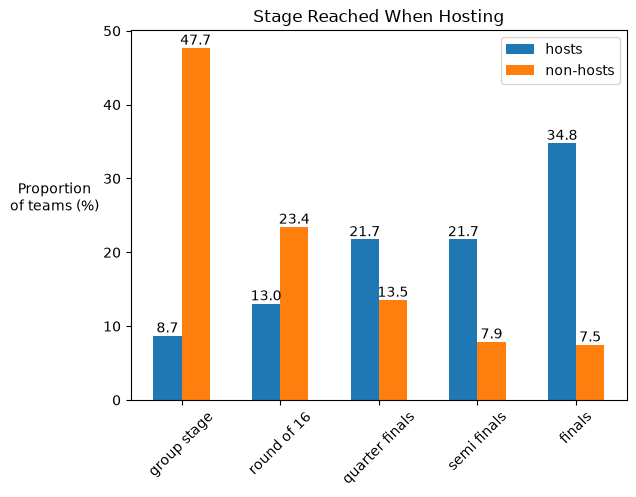

In [262]:
'''Stage Reached When Hosting'''

plt.grouped_bar([mens_hosts_agg["proportion"], squad_exp_perform_nonhosts["proportion"]], tick_labels=stage_names, labels=["hosts", "non-hosts"])
plt.xticks(rotation=45)
plt.title('Stage Reached When Hosting')
plt.ylabel('Proportion\nof teams (%)', rotation=0, labelpad=35)
plt.legend()

ax = plt.gca()

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')

Significant trend of host countries reaching the later stages when they host, versus non-hosting teams had the downward trend of not reaching later stages.  
Hosts reached the finals in nearly 35% of World Cups, compared to non-hosts reaching the final in only 7.5% of World Cups.

### Penalties analysis

In [263]:
'''Exclude women's tournaments.
N.B: It is understood that penalties within this dataset refer to penalties taken in extra time, not within matches due to fouls etc'''

mens_pens = penalties[~penalties['tournament_name'].str.contains('Women')]
mens_pens.head()

,key_id,penalty_kick_id,tournament_id,tournament_name,match_id,match_name,match_date,stage_name,group_name,team_id,team_name,team_code,home_team,away_team,player_id,family_name,given_name,shirt_number,converted
0,1,PK-001,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-68969,Kaltz,Manfred,20,1
1,2,PK-002,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-48686,Breitner,Paul,3,1
2,3,PK-003,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-45695,Stielike,Uli,15,0
3,4,PK-004,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-89975,Littbarski,Pierre,7,1
4,5,PK-005,WC-1982,1982 FIFA Men's World Cup,M-1982-50,West Germany vs France,1982-07-08,semi-finals,not applicable,T-86,West Germany,DEU,1,0,P-59574,Rummenigge,Karl-Heinz,11,1


In [264]:
''' Aggregated mens penalties dataframe to capture round_reached'''

mens_pens_agg = mens_pens.groupby(['tournament_id', 'team_name']).\
    agg(sum_converted_pens=('converted', 'sum'), total_pens=('converted', 'count')).reset_index()

mens_pens_agg['pct_converted'] = round((mens_pens_agg['sum_converted_pens'] / mens_pens_agg['total_pens']) * 100)
mens_pens_agg = pd.merge(mens_pens_agg, squad_exp_perform[['tournament_id', 'team_name','round_reached']], how='left', on=['tournament_id', 'team_name'])

In [265]:
''' Remove Group Stage as there were no penalties here '''

stage_order_edit = [x for x in stage_order if x != 'Group Stage']

C:\Users\bevamin\AppData\Local\Temp\ipykernel_34436\3759119149.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=mens_pens_agg, x='stage_name', y='pct_converted', order=stage_order_edit, palette='Set2')


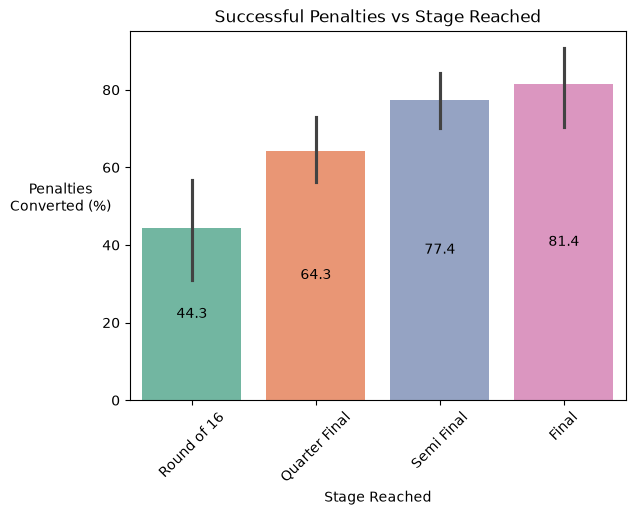

In [266]:
''' Successful Penalties vs Stage Reached '''

stage_map = {
    2: 'Round of 16',
    3: 'Quarter Final',
    4: 'Semi Final',
    5: 'Final'
}

mens_pens_agg['stage_name'] = mens_pens_agg['round_reached'].map(stage_map)

sns.barplot(data=mens_pens_agg, x='stage_name', y='pct_converted', order=stage_order_edit, palette='Set2')
plt.ylabel("Penalties\nConverted (%)", rotation=0, labelpad=30)
plt.xlabel("Stage Reached")
plt.xticks(rotation=45)
plt.title('Successful Penalties vs Stage Reached')

ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', label_type='center')

Clear trend shown of a higher number of successful penalty shots leading to teams reaching the final stages, with only ~20% of penalties missed in the finals matches.

## 5. Machine Learning Analysis

### Predict Tournament Progression
- Can squad characteristics predict how far a country will progress in the World Cup?

In [267]:
''' Add column to see who won the tournament that year'''

squad_exp_perform = pd.merge(squad_exp_perform, tourn_winners_mens, on='tournament_id', how='left')

''' Rename column for clarity '''
squad_exp_perform = squad_exp_perform.rename(columns={'winner': 'tourn_winner_that_yr'})

''' Column to check if the team in that row won that year or not'''
squad_exp_perform['won?'] = squad_exp_perform.apply(lambda row: True if row['team_name'] == row['tourn_winner_that_yr'] else False, axis=1)

''' Column to get a True/False if the team hosted that year '''
squad_exp_perform['hosted?'] = squad_exp_perform.apply(lambda row: True if row['team_name'] == row['host_name'] else False, axis=1)

In [268]:
# converted tournament progression into a numerical scale so that it could be analysed quantitatively.

''' Reassign rankings - previously for simplicity, these were more condensed and didn't capture winner'''
new_performance_rank = {
    'group stage': 1,
    'round of 16': 2,
    'second group stage': 3,
    'quarter-finals': 4,
    'semi-finals': 5,
    'third-place match': 6,
    'final': 7,
    'final round': 7
}

'''map new stages onto previous dataframe containing string value of performance'''
mens_squads['new_perform_rank'] = (mens_squads['performance'].map(new_performance_rank))

'''Condense into 1 row per team per tournament instead of per player per team per tournament'''
mens_squads_for_merge = mens_squads.groupby(['team_name', 'tournament_id'])['new_perform_rank'].mean().reset_index()

'''merge with current dataframe to get final new granular rankings'''
squad_exp_perform = pd.merge(squad_exp_perform, mens_squads_for_merge, on=['tournament_id', 'team_name'], how='left')
squad_exp_perform.loc[squad_exp_perform['won?'], 'new_perform_rank'] = 8

'''merge penalties df to get successful penalties % into squad_exp_perfom '''
squad_exp_perform = pd.merge(squad_exp_perform, mens_pens_agg[['tournament_id', 'team_name', 'pct_converted']], how='left', on=['tournament_id', 'team_name'])
squad_exp_perform.rename(columns={'pct_converted': 'penalties_converted'}, inplace=True)


In [269]:
print(squad_exp_perform.columns)

Index(['tournament_id', 'team_name', 'team_total_matches', 'avg_games_played',
       'median_games_played', 'max_games_played', 'round_reached',
       'subs_count', 'subs_per_game', 'avg_performance_alltime',
       'median_performance_alltime', 'max_performance_alltime', 'ever_won_wc',
       'avg_age', 'median_age', 'max_age', 'defender', 'forward',
       'goal keeper', 'midfielder', 'squad_size', 'goal keeper_pct',
       'defender_pct', 'midfielder_pct', 'forward_pct', 'no_goals',
       'no_unique_scorers', 'no_uniq_scorer_per_goal', 'key_id',
       'tournament_name', 'team_id', 'host_name', 'team_code', 'perform_map',
       'tourn_winner_that_yr', 'won?', 'hosted?', 'new_perform_rank',
       'penalties_converted'],
      dtype='str')


In [270]:
''' Target variable (y)'''
y = squad_exp_perform['new_perform_rank']

In [271]:
# These variables were selected because previous analyses suggested they may have some relationship with tournament success.

''' Predictor variables '''
features = ['no_uniq_scorer_per_goal', 'penalties_converted']
x = squad_exp_perform[features]

In [272]:
# Teams with incomplete records were excluded to ensure fair comparisons across all observations.

''' remove missing values '''
model_df = pd.concat([x, y], axis=1).dropna()
x = model_df[features]
y = model_df['new_perform_rank']

In [273]:
# 80% training data
# 20% testing data
# hold back 20% of the data and use this as an independent test

''' train/test split '''
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [274]:
# The regression calculates how much each factor contributes to explaining tournament success 
# while accounting for the influence of the other variables.

''' fit the model '''
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[1.12,0.05]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['no_uniq_scorer_per_goal','penalties_converted']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.3617
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [275]:
''' make predictions '''
predictions = model.predict(X_test)
predictions

array([7.71978407, 4.74382894, 5.70413326, 5.08819713, 4.46762726,
       2.36788393, 5.40543267, 5.86410555, 4.74757876, 5.83473447,
       5.86410555, 5.592067  , 5.54917965, 2.61425838, 2.96048006])

In [276]:
''' evaluate performance (0 = no predictive power, 0.2 = weak, 0.4 = moderate, 0.6+ = strong)'''
r2 = r2_score(y_test, predictions)
print(r2)

0.2758081246570361


Approximately 28% of the differences in tournament performance can be explained by the variables included in the model.

In [277]:
# This measures how far off the predictions were on average.
''' Mean Absolute Error '''
mae = mean_absolute_error(y_test, predictions)
print(mae)

1.1452937494925128


On average, the model's prediction was approximately 1.14 tournament stages away from the actual result.

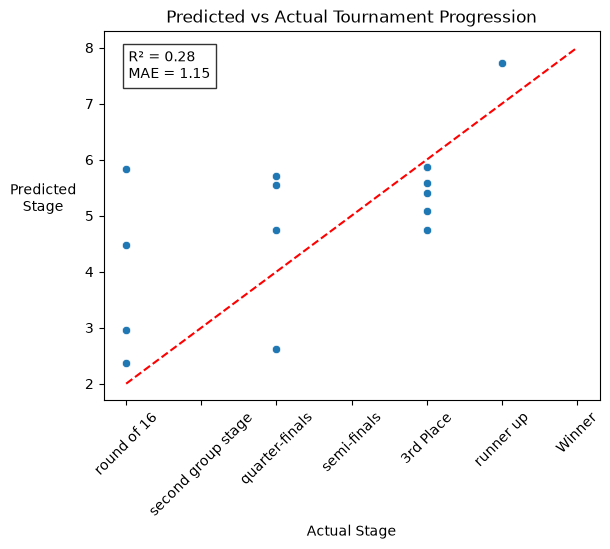

In [278]:
''' Predicted vs Actual Plot'''

sns.scatterplot(x=y_test, y=predictions)

plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    'r--')

plt.text(
    0.05, 0.95,
    f'R² = {r2:.2f}\nMAE = {mae:.2f}',
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.8)
)

plt.xlabel('Actual Stage')
plt.ylabel('Predicted\nStage', rotation=0, labelpad=30)
plt.title('Predicted vs Actual Tournament Progression')
stage_list_for_x = ['round of 16','second group stage','quarter-finals','semi-finals','3rd Place','runner up','Winner']
plt.xticks([2, 3, 4, 5, 6, 7, 8], stage_list_for_x, rotation=45)
plt.show()

Points close to line = good predictions.
Points far away = poor predictions.

In [279]:
''' feature importance '''

coef_df = pd.DataFrame({
    'Feature': x.columns,
    'Coefficient': model.coef_
})

coef_df = coef_df.sort_values(
    by='Coefficient',
    ascending=False
)

print(coef_df)

                   Feature  Coefficient
0  no_uniq_scorer_per_goal     1.119806
1      penalties_converted     0.049460


The coefficients show the direction and size of each relationship.

C:\Users\bevamin\AppData\Local\Temp\ipykernel_34436\3963589517.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


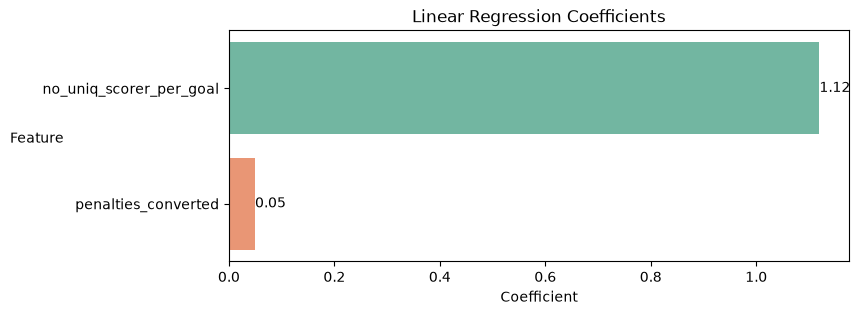

In [280]:
''' plot coefficients '''

fig = plt.figure(figsize=(8, 3))
ax = sns.barplot(
    data=coef_df,
    x='Coefficient',
    y='Feature', palette='Set2')

plt.title('Linear Regression Coefficients')
plt.ylabel('Feature', rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')

- Positive coefficient → increases predicted progression.  
- Negative coefficient → decreases predicted progression.

Higher number of unique scorers per goal, as well as the country hosting the world cup, were the 2 highest factors associated with better tournament performance.

In [281]:
''' Statistical significance '''

X_sm = sm.add_constant(x)
model_sm = sm.OLS(y, X_sm).fit()

print(model_sm.summary())
# important: P>|t|
# if p < 0.05, then that variable is statistically significant

                            OLS Regression Results                            
Dep. Variable:       new_perform_rank   R-squared:                       0.451
Model:                            OLS   Adj. R-squared:                  0.435
Method:                 Least Squares   F-statistic:                     27.92
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           1.40e-09
Time:                        14:35:39   Log-Likelihood:                -125.87
No. Observations:                  71   AIC:                             257.7
Df Residuals:                      68   BIC:                             264.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

## 6. Conclusions

### Factors NOT showing significance/trends vs World Cup stage reached:
- Substitutions per game
- Average squad age
- Squads having different proportions of positions i.e.- goal keeper, defender, midfielder, and forward percentage makeup
- Percentage of players retained from the previous World Cup year
- In terms of distribution of match goals across the match duration: champion-winning teams and non champion-winning teams both score slightly more goals in the later part of the matches, however there were hardly any goals in 90+mins as both teams are likely playing more defensively

### Factors which DID show some significance/trends vs World Cup stage reached:
- Winning teams get slightly more goals from forwards vs non-winning teams.
- Higher numbers of unique scorers per goal
- Winning nations had managers from their own country in 83.9% of tournaments, compared with 62.3% for non-winning nations.
- Significant trend of host countries reaching the later stages when they host, versus non-hosting teams had the downward trend of not reaching later stages. Hosts reached the finals in nearly 35% of World Cups, compared to non-hosts reaching the final in only 7.5% of World Cups.
- Clear trend shown of a higher number of successful penalty shots leading to teams reaching the final stages, with only ~20% of penalties missed in the finals matches.

#### Insights from 1st notebook (01-exploration.ipynb):
##### General player attributes:
- Reaction time was strongly positively correlated against success outcomes such as overall rating and market value.
- Composure, ball control, and short passing versus success outcomes were the next three characteristics which were moderately positively correlated.
- Player age and potential were weakly negatively correlated, indicating that younger players were deemed as having more potential than older players.  

##### Other:
- Teams with higher overall mean player ratings correlated positively (R2 = 0.59) with mean team market value.

#### Machine Learning Insights:
- Number of unique scorers per goal and penalty conversion rate were significant predictors of tournament progression ((p < 0.001) for both, showing a statistically significant positive relationship with tournament progression), while whether the team hosted was not.  
- **Teams with higher penalty conversion rates and higher numbers of unique scorers generally advanced further in the competition.**
